# Section 2: Data Inspection, Statistics & Missing Values
Noura Alaqeel

**Team rules:** drop `enrollee_id` · no mean/median/mode imputation (no leakage) · no encoding/scaling here.

## Part A: Data Inspection

Load the raw data, drop `enrollee_id`, convert `target` to int and show the first rows.

In [1]:
# Load data and drop ID
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Dataset/raw_kaggle_data.csv")
df = df.drop(columns=["enrollee_id"])
df["target"] = df["target"].astype(int)
print(df.shape)
df.head()

(19158, 13)


,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1
1,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0
2,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0
3,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1
4,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0


Summary table per column: type, unique values and missing values.

In [2]:
# Per-column summary table
pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(2),
})

,dtype,n_unique,n_missing,pct_missing
city,str,123,0,0.00
city_development_index,float64,93,0,0.00
gender,str,3,4508,23.53
relevent_experience,str,2,0,0.00
enrolled_university,str,3,386,2.01
education_level,str,5,460,2.40
major_discipline,str,6,2813,14.68
experience,str,22,65,0.34
company_size,str,8,5938,30.99
company_type,str,6,6140,32.05


Data-quality checks: drop duplicates, count cities, list `company_size` labels.

In [3]:
# Duplicates, cities, labels
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape:", df.shape)
print("Cities:", df["city"].nunique())
print("company_size values:", sorted(df["company_size"].dropna().unique()))

Duplicates: 49
Shape: (19109, 13)
Cities: 123
company_size values: ['10/49', '100-500', '1000-4999', '10000+', '50-99', '500-999', '5000-9999', '<10']


## Part B: Statistics

Descriptive statistics and skewness of the two numeric columns.

In [4]:
# Numeric statistics and skewness
num = ["city_development_index", "training_hours"]
display(df[num].describe())
df[num].skew()

,city_development_index,training_hours
count,19109.000000,19109.000000
mean,0.828697,65.442200
std,0.123401,60.098917
min,0.448000,1.000000
25%,0.740000,23.000000
50%,0.903000,47.000000
75%,0.920000,88.000000
max,0.949000,336.000000


city_development_index   -0.993066
training_hours            1.817132
dtype: float64

Target balance: count and % of each class, with a bar chart.

        count    pct
target              
0       14344  75.06
1        4765  24.94


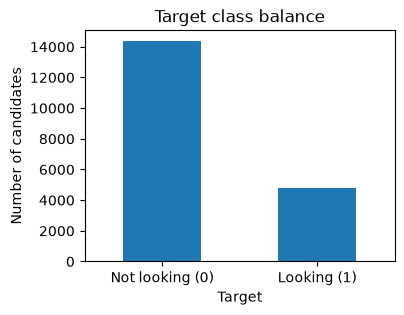

In [5]:
# Target balance and chart
counts = df["target"].value_counts()
print(pd.DataFrame({"count": counts, "pct": (counts / len(df) * 100).round(2)}))
ax = counts.plot(kind="bar", figsize=(4, 3))
ax.set_title("Target class balance")
ax.set_xlabel("Target")
ax.set_ylabel("Number of candidates")
ax.set_xticklabels([{0: "Not looking (0)", 1: "Looking (1)"}[i] for i in counts.index], rotation=0)
plt.show()

**Interpretation:** 75.06% are not looking (14,344) vs 24.94% looking for a job change (4,765), about 3:1, so accuracy alone would be misleading.

Job-change rate (%) per category for three columns, and by city development index band.

In [6]:
# Job-change rate per category
for col in ["relevent_experience", "experience", "company_type"]:
    rate = df.groupby(df[col].fillna("(missing)"))["target"].mean() * 100
    print(rate.round(1).sort_values(ascending=False))
    print()
band = pd.cut(df["city_development_index"], [0, 0.6, 0.7, 0.8, 0.9, 1.0])
(df.groupby(band, observed=True)["target"].mean() * 100).round(1)

relevent_experience
No relevent experience     33.8
Has relevent experience    21.5
Name: target, dtype: float64

experience
<1           45.3
1            42.4
(missing)    35.4
3            35.3
2            33.1
4            32.5
7            29.4
5            28.8
6            28.2
8            24.3
11           22.7
20           22.3
9            21.8
10           21.0
13           19.3
12           18.6
14           18.3
19           17.4
17           16.7
15           16.7
18           15.4
>20          15.3
16           14.2
Name: target, dtype: float64

company_type
(missing)              38.8
Other                  24.0
Early Stage Startup    23.5
Public Sector          22.0
NGO                    18.6
Pvt Ltd                18.1
Funded Startup         14.0
Name: target, dtype: float64



city_development_index
(0.0, 0.6]    57.9
(0.6, 0.7]    49.6
(0.7, 0.8]    24.7
(0.8, 0.9]    13.6
(0.9, 1.0]    16.8
Name: target, dtype: float64

## Part C: Missing Values

Percentage of missing values per column, with a bar chart.

company_type           32.04
company_size           30.98
gender                 23.59
major_discipline       14.70
education_level         2.41
last_new_job            2.21
enrolled_university     2.02
experience              0.34
dtype: float64


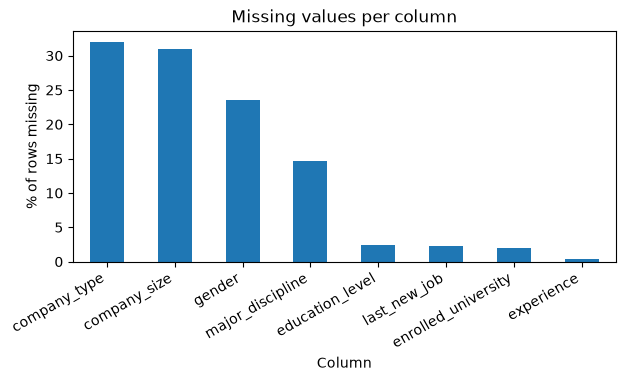

In [7]:
# Percent missing per column
miss = (df.isna().mean() * 100).round(2)
miss = miss[miss > 0].sort_values(ascending=False)
print(miss)
ax = miss.plot(kind="bar", figsize=(7, 3))
ax.set_title("Missing values per column")
ax.set_xlabel("Column")
ax.set_ylabel("% of rows missing")
plt.xticks(rotation=30, ha="right")
plt.show()

Job-change rate (%) when each column is missing vs present.

In [8]:
# Rate: missing vs present
pd.DataFrame({
    "rate_missing": [df.loc[df[c].isna(), "target"].mean() * 100 for c in miss.index],
    "rate_present": [df.loc[df[c].notna(), "target"].mean() * 100 for c in miss.index],
}, index=miss.index).round(1)

,rate_missing,rate_present
company_type,38.8,18.4
company_size,40.6,17.9
gender,30.8,23.1
major_discipline,19.5,25.9
education_level,22.6,25.0
last_new_job,36.4,24.7
enrolled_university,31.9,24.8
experience,35.4,24.9


**Interpretation:** when `company_type` is missing the job-change rate is 38.8% vs 18.4% when present (`company_size`: 40.6% vs 17.9%), so missingness is informative and is kept as `Unknown`.

Apply the fixed cleaning rules, check that nothing is missing and save `Dataset/cleaned_data.csv`.

In [9]:
# Clean, verify and save
clean = df.copy()
clean["company_size"] = clean["company_size"].replace("10/49", "10-49")
school = clean["education_level"].isin(["Primary School", "High School"]) & clean["major_discipline"].isna()
clean.loc[school, "major_discipline"] = "No Major"
cols = ["company_type", "company_size", "gender", "major_discipline", "enrolled_university", "education_level"]
clean[cols] = clean[cols].fillna("Unknown")
clean = clean.dropna(subset=["experience", "last_new_job"]).reset_index(drop=True)
print("Missing left:", clean.isna().sum().sum())
print("Shape:", clean.shape)
clean.to_csv("Dataset/cleaned_data.csv", index=False)

Missing left: 0
Shape: (18645, 13)


**Interpretation:** 0 missing values are left and the cleaned data has 18,645 rows × 13 columns (97.3% of the 19,158 raw rows).

## Part D: Key Insights

### Key Insights
- **Imbalanced target:** 24.9% are looking for a job change vs 75.1% not looking (about 3:1).
- **City development is the strongest signal:** job-change rate is 57.9% when CDI ≤ 0.6 vs 13.6–16.8% when CDI > 0.8. CDI is skewed left (−0.99), training_hours skewed right (1.82).
- **Less experience means more likely to look for a job change:** 45.3% for <1 year vs 15.3% for >20 years; 33.8% with no relevant experience vs 21.5% with it.
- **Missing values are informative:** company_type (32.0%) and company_size (31.0%) are missing most, and 38.8% and 40.6% of those rows are looking for a job change vs about 18% when present, so they were filled with 'Unknown' instead of dropped or mode-filled.
- **Clean result:** 19,158 raw rows → 18,645 rows × 13 columns with 0 missing (49 duplicates and 464 rows missing experience/last_new_job dropped).

**For Tojan (preprocessing):** use `Dataset/cleaned_data.csv`; `target` is already int 0/1; ordinal columns (experience, last_new_job, company_size, education_level) need an ordered mapping; `city` duplicates `city_development_index`, so one of them is enough.
